# srFRC — local resolution mapping

## Import the analysis functions

Import `RollingFourierRingCorrelation` from `src` together with the image-loading tools. The analyzer automatically plots the current-frame resolution map using its built-in plotting function. Resolution and pixel size are in **nm**; background intensity thresholds use the **0–255** scale.


In [5]:
from pathlib import Path
import sys
import numpy as np
import tifffile
import matplotlib.pyplot as plt

# Support notebooks launched from the repository root or demos/.
repo = Path.cwd().resolve()
if not (repo / 'src' / 'sFRC.py').is_file():
    repo = repo.parent
if not (repo / 'src' / 'sFRC.py').is_file():
    raise RuntimeError('Run this notebook from the repository root or demos/ directory.')
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
example_dir = repo / 'example_data'

from src.srFRC import RollingFourierRingCorrelation


## 1. Load the input image

Use one acquired frame for single-frame srFRC. When the input TIFF contains multiple frames, select which frame to analyze. Provide its original calibrated pixel size; the internal complementary-pair construction handles resampling.

Image shape: (1024, 1024)


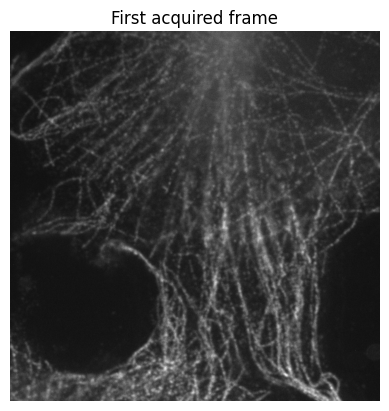

In [6]:
input_file = example_dir / 'c6-2s.tif'
if not input_file.is_file():
    raise FileNotFoundError(f'Add the TIFF file: {input_file}')
input_stack = tifffile.imread(input_file)
image = input_stack if input_stack.ndim == 2 else input_stack[0]
pixel_size_nm = 38.2  # Update to match your actual acquisition.
print('Image shape:', image.shape)
plt.imshow(image, cmap='gray')
plt.title('First acquired frame')
plt.axis('off')
plt.show()

## 2. Calculate the local resolution map (serial)

The default single-frame analysis uses a **64-pixel block**, **2-pixel step**, **1.0× Otsu** adaptive background and the **3-sigma** FRC criterion. Only `parallel=False` is specified below to demonstrate serial execution; the default plotting function displays the current-frame map automatically. The reported computation time excludes plotting and export.

srFRC - background threshold: 59.08 (intensity scale 0-255)


rolling resolution calculation: 100%|██████████████████████████████████████| 65536/65536.0 [09:46<00:00, 111.66pixel/s]


srFRC - numerical computation time: 587.135 s (excludes plotting and file export).
  bg0.8: 587.116 s
srFRC - completed 1 background group(s): bg0.8.


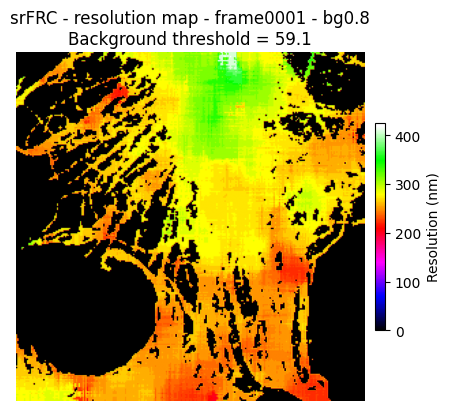

Adaptive background multipliers: [0.8]
Applied background thresholds (0–255): {'bg0.8': [59.08148956298828]}
Computation time (s): 587.1354938000004
Native-grid statistics: [1.99575516e+02 4.25182617e+02 2.69078186e+02 3.48252492e-01]


In [7]:
serial = RollingFourierRingCorrelation(pixel_size=pixel_size_nm, parallel=False)
serial.execute(image)
print('Adaptive background multipliers:', serial.get_ratios())
print('Applied background thresholds (0–255):', serial.final_background_thresholds)
print('Computation time (s):', serial.computation_time_seconds)
print('Native-grid statistics:', serial.calculate_global())


## 3. Compare serial and parallel execution

This optional section repeats the calculation using the default `parallel=True`, leaving all numerical settings unchanged. Compare the results and computation times; the parallel map is plotted automatically. On small images, process-management overhead may make parallel execution slower.

srFRC - background threshold: 59.08 (intensity scale 0-255)
Processing 64 patches...


patch processing: 100%|█████████████████████████████████████████████████████████████| 64/64 [00:44<00:00,  1.43patch/s]


srFRC - parallel map calculation complete.
srFRC - numerical computation time: 45.421 s (excludes plotting and file export).
  bg0.8: 45.399 s
srFRC - completed 1 background group(s): bg0.8.


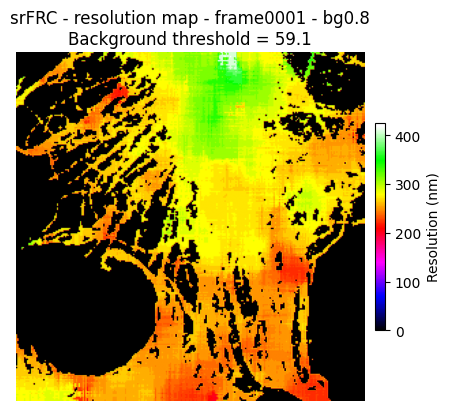

Serial computation (s): 587.1354938000004
Parallel computation (s): 45.42107019999821
Maximum map difference (nm): 0.0
Parallel native-grid statistics: [1.99575516e+02 4.25182617e+02 2.69078186e+02 3.48252492e-01]


In [8]:
run_parallel = True
if run_parallel:
    parallel = RollingFourierRingCorrelation(pixel_size=pixel_size_nm)
    parallel.execute(image)
    print('Serial computation (s):', serial.computation_time_seconds)
    print('Parallel computation (s):', parallel.computation_time_seconds)
    print('Maximum map difference (nm):',
          np.nanmax(np.abs(serial.get_rfrc_map() - parallel.get_rfrc_map())))
    print('Parallel native-grid statistics:', parallel.calculate_global())


## 4. Optional second sample for background analysis

Replace the filename and pixel calibration below with those of another acquisition. The next sections are disabled until you enable them and supply the file.

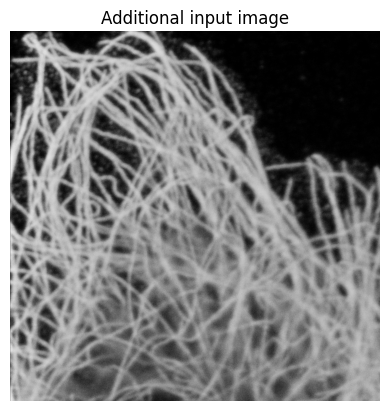

In [9]:
run_background_example = True
other_file = example_dir / 'c3.tif'
other_pixel_size_nm = 20  # Enter the new acquisition calibration.

if run_background_example:
    if not other_file.is_file():
        raise FileNotFoundError(f'Add the TIFF file: {other_file}')
    if other_pixel_size_nm is None:
        raise ValueError('Set other_pixel_size_nm before running the second sample.')
    other_stack = tifffile.imread(other_file)
    other_image = other_stack if other_stack.ndim == 2 else other_stack[0]
    plt.imshow(other_image, cmap='gray')
    plt.title('Additional input image')
    plt.axis('off')
    plt.show()


## 5. Monitor the effect of background threshold selection

Local srFRC assigns a resolution estimate to each rolling window, excluding windows dominated by background. An overly high background cutoff can leave large empty regions in the map, whereas a low cutoff admits more noise-dominated windows. **`monitor_change=True`** tests how sensitive the local map is to this choice by running **0.6×, 0.8× and 1.0× the Otsu threshold**.

Setting `monitor_change=True` automatically disables the usual adaptive-background mode and produces three separately calculated maps. The built-in display places the **three resolution maps in one row** with a common sJet color scale; each title shows its **absolute intensity threshold**, e.g. `Background threshold = 42.5`. These background cutoffs determine which windows are analyzed and are **distinct from the 3σ or 1/7 Fourier-correlation criterion**. See [srFRC background parameter relationships](../docs/advancedParameters.md#srfrc-background-parameter-relationships).


srFRC - background mode: monitor_change=True disables adaptive_background. Comparing Otsu multipliers 0.8, 1.0, and 1.2; background_threshold is ignored.
srFRC - background threshold: 54.09 (intensity scale 0-255)
Processing 256 patches...


patch processing: 100%|███████████████████████████████████████████████████████████| 256/256 [03:17<00:00,  1.30patch/s]


srFRC - parallel map calculation complete.
srFRC - background threshold: 72.12 (intensity scale 0-255)
Processing 256 patches...


patch processing: 100%|███████████████████████████████████████████████████████████| 256/256 [03:12<00:00,  1.33patch/s]


srFRC - parallel map calculation complete.
srFRC - background threshold: 90.15 (intensity scale 0-255)
Processing 256 patches...


patch processing: 100%|███████████████████████████████████████████████████████████| 256/256 [03:03<00:00,  1.39patch/s]


srFRC - parallel map calculation complete.
srFRC - numerical computation time: 575.987 s (excludes plotting and file export).
  bg0.6: 197.832 s
  bg0.8: 193.644 s
  bg1.0: 184.493 s
srFRC - completed 3 background group(s): bg0.6, bg0.8, bg1.0.


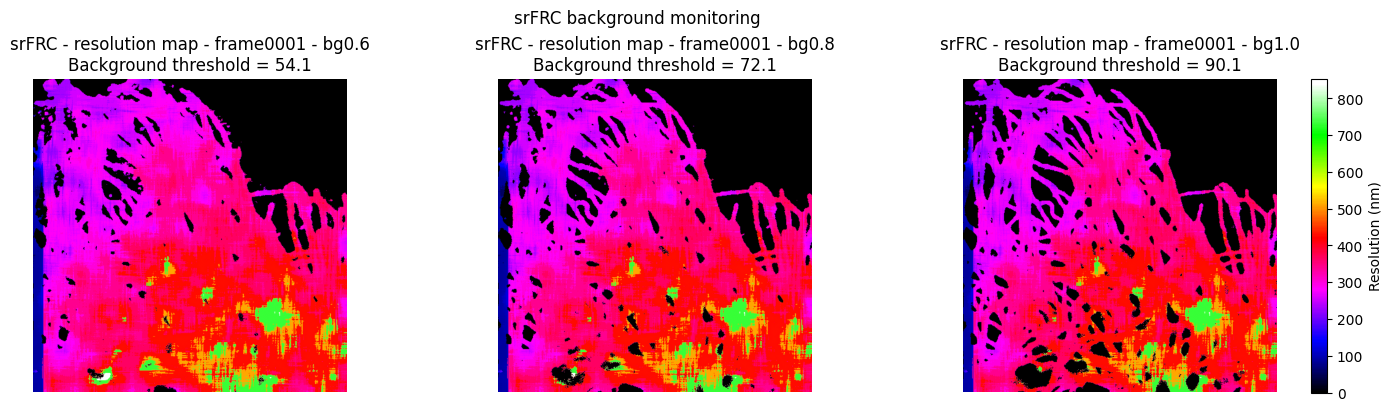

Computation time (s): 575.9866339
Background thresholds: {'bg0.6': [54.087890625], 'bg0.8': [72.1171875], 'bg1.0': [90.146484375]}
Native-grid statistics: {'bg0.6': array([ 52.96551895, 853.33331299, 357.40937206,   5.74796319]), 'bg0.8': array([ 52.96551895, 853.33331299, 357.59041446,   5.75138131]), 'bg1.0': array([ 52.96551895, 853.33331299, 356.59743379,   5.73263362])}


In [10]:
if run_background_example:
    monitoring = RollingFourierRingCorrelation(
        pixel_size=other_pixel_size_nm, monitor_change=True)
    monitoring.execute(other_image)
    print('Computation time (s):', monitoring.computation_time_seconds)
    print('Background thresholds:', monitoring.final_background_thresholds)
    print('Native-grid statistics:', monitoring.calculate_global())


## 6. Apply a manual background threshold

After inspecting the background comparison, a fixed intensity threshold can be selected using `background_threshold` with both background switches disabled. The threshold is on the **0–255 intensity scale** and changes which local windows are evaluated, not the Fourier-correlation criterion.


Processing 256 patches...


patch processing: 100%|███████████████████████████████████████████████████████████| 256/256 [02:43<00:00,  1.57patch/s]


srFRC - parallel map calculation complete.
srFRC - numerical computation time: 164.344 s (excludes plotting and file export).
  manual-bg: 164.320 s
srFRC - completed 1 background group(s): manual-bg.


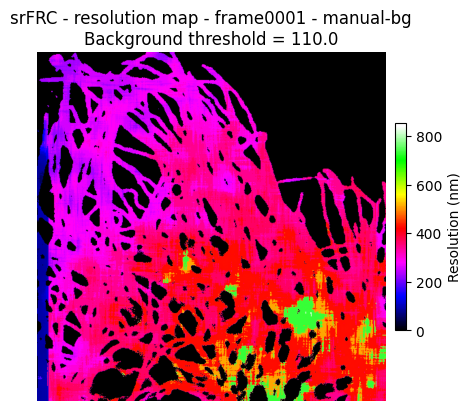

Computation time (s): 164.34361830000125
Native-grid statistics: [ 52.96551895 853.33331299 354.24188656   5.6881604 ]


In [11]:
manual_threshold = 110  # Example only; choose based on this sample's intensity.
if run_background_example:
    manual = RollingFourierRingCorrelation(
        pixel_size=other_pixel_size_nm,
        adaptive_background=False,
        background_threshold=manual_threshold)
    manual.execute(other_image)
    print('Computation time (s):', manual.computation_time_seconds)
    print('Native-grid statistics:', manual.calculate_global())
